In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = yf.download("SPY", start="2010-01-01", end="2025-12-20")
data = df["Close"].dropna()

[*********************100%***********************]  1 of 1 completed


In [41]:
print('Missing prices:', data.isna().sum())

print('Non-positive prices:', (data <= 0).sum())

print('Duplicate dates:', data.index.duplicated().sum())

all_dates = pd.date_range(
    start=data.index.min(),
    end=data.index.max(),
    freq='B'
)

missing_dates = all_dates.difference(data.index)
print('Potential missing dates:', missing_dates)

Missing prices: Ticker
SPY    0
dtype: int64
Non-positive prices: Ticker
SPY    0
dtype: int64
Duplicate dates: 0
Potential missing dates: DatetimeIndex(['2010-01-18', '2010-02-15', '2010-04-02', '2010-05-31',
               '2010-07-05', '2010-09-06', '2010-11-25', '2010-12-24',
               '2011-01-17', '2011-02-21',
               ...
               '2025-01-01', '2025-01-09', '2025-01-20', '2025-02-17',
               '2025-04-18', '2025-05-26', '2025-06-19', '2025-07-04',
               '2025-09-01', '2025-11-27'],
              dtype='datetime64[us]', length=148, freq=None)


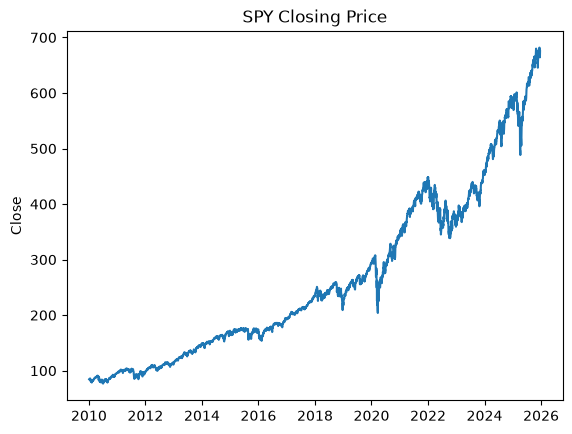

In [48]:
data.to_csv("cleaned_prices.csv")

plt.plot(data)
plt.ylabel('Close')
plt.title('SPY Closing Price')
plt.show()

Text(0.5, 1.0, 'SPY Daily log Returns')

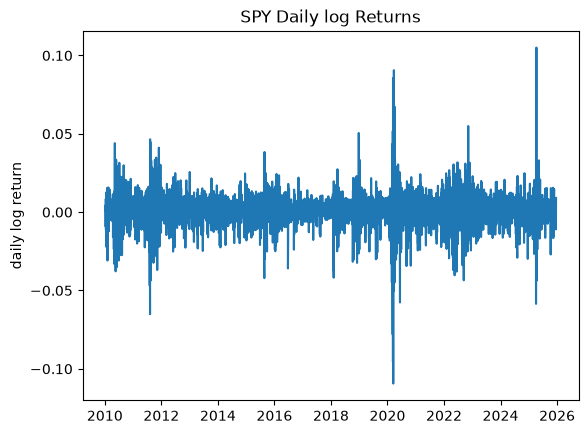

In [50]:
log_returns = np.log(data / data.shift(1)).dropna()
log_returns.to_csv("log_return.csv")

plt.plot(daily_returns)
plt.ylabel('daily log return')
plt.title('SPY Daily log Returns')

In [35]:
daily_vol = log_returns.std().item()
print(f"Historical daily volatility: {daily_vol: .2%}")

annualized_vol = daily_vol*np.sqrt(252)
print(f"Historical annualized volatility: {annualized_vol: .2%}")

Historical daily volatility:  1.09%
Historical annualized volatility:  17.26%


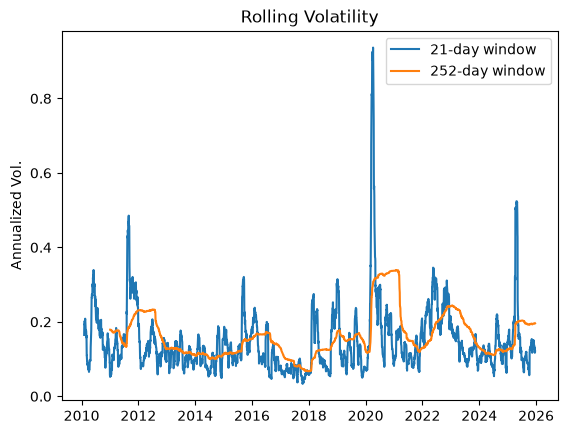

In [47]:
window1 = 21
window2 = 252
rolling_vol1 = log_returns.rolling(window1).std()*np.sqrt(252)
rolling_vol2 = log_returns.rolling(window2).std()*np.sqrt(252)
plt.plot(rolling_vol1, label=f"{window1}-day window")
plt.plot(rolling_vol2, label=f"{window2}-day window")
plt.ylabel('Annualized Vol.')
plt.title('Rolling Volatility')
plt.legend()
plt.show()

Depending on the window size, we can receive very different pictures of the realized volatility. The shorter window reacts more quickly and violently to market movements, while the longer window is delayed and more smooth. Volatility appears to cluster more with the longer window, while it is more sporatic with the smaller. 